# trPL simulation

In [1]:
import os, sys
try:
    import pySIMsalabim as sim
except ImportError: # add parent directory to sys.path if pySIMsalabim is not installed
    sys.path.append('..')
    import pySIMsalabim as sim
from pySIMsalabim.experiments.trPL import *

# Use the default input files shipped with the pySIMsalabim tests (pySIMsalabim/tests/sim_inputs/default):
# check that they match the SIMsalabim version and copy them into SIMsalabim/SimSS and SIMsalabim/ZimT
sys.path.append(os.path.join('..', 'pySIMsalabim', 'tests'))
from sim_inputs_setup import prepare_test_inputs, cleanup_test_inputs
prepare_test_inputs(convert=False)

Test inputs for SimSS: version matches SIMsalabim 5.37
Test inputs for ZimT: version matches SIMsalabim 5.37
Copying the SimSS test inputs to /home/lecorre/Desktop/pySIMsalabim/SIMsalabim/SimSS
Copying the ZimT test inputs to /home/lecorre/Desktop/pySIMsalabim/SIMsalabim/ZimT


### Setup the simulation

In [2]:
# Set the path to the simulation setup file
cwd = os.path.abspath('..')
session_path = os.path.join(cwd, 'SIMsalabim','ZimT')
zimt_device_parameters = os.path.join(session_path, 'simulation_setup_trPL_test.txt')

# Set the trPL simulation parameters
lyr_idx = 1
t_max = 1E-7
t_step = 1E-9
t_pulse = 10E-9
t_scale = 'log'
FWHM = 3E-9
steps = 250
ret, mess = run_trPL_simu(zimt_device_parameters, session_path, lyr_idx, t_max, t_scale, t_step, t_pulse, FWHM, steps=steps, output_file = 'trPL.dat', tj_name = 'tj.dat')


### Plot results

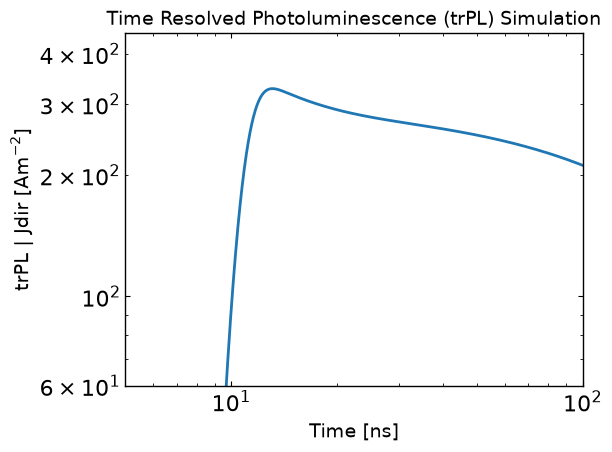

In [3]:
plot_trPL(session_path, output_file = 'trPL.dat', xlim = [5E-9,1E-7], ylim = [60,450])

In [4]:
num_pulses = 5
freq = 10e3
ret, mess = run_trPL_simu(zimt_device_parameters, session_path, lyr_idx, t_max, t_scale, t_step, t_pulse, FWHM, num_pulses = num_pulses, freq = freq, output_file = 'trPL_multi.dat', tj_name = 'tj.dat',steps=250)


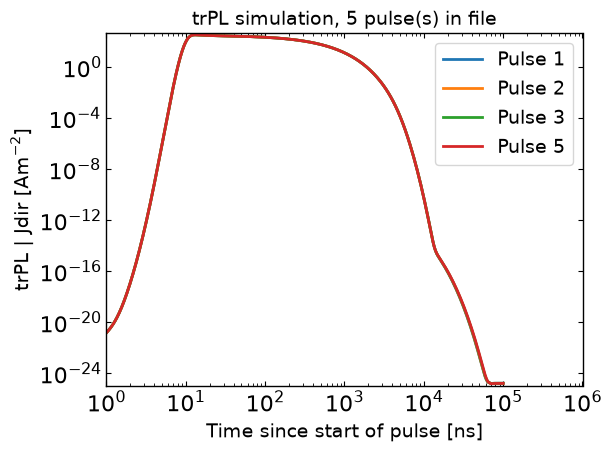

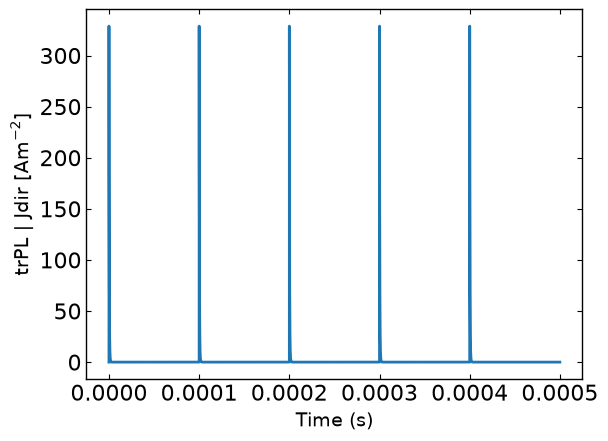

In [5]:
plot_trPL_pulse(session_path, output_file = 'trPL_multi.dat', freq = freq, t_pulse = t_pulse, pulse=[1,2,3,-1], xlim=[1E-9, 1E-3], ylim=[1E-25, 4.5E2])

# Plot the tj File to see the full temporal response
trPL_data = pd.read_csv(os.path.join(session_path, 'tj.dat'), sep=r'\s+')
plt.figure()
plt.plot(trPL_data['t'], trPL_data['JdirL1'])
plt.xlabel('Time (s)')
plt.ylabel('trPL | Jdir [Am$^{-2}$]')
plt.show()

In [6]:
# Clean up the output files (comment out if you want to keep the output files)
sim.clean_all_output(session_path)
sim.clean_up_output('trPL',session_path)
sim.delete_folders('tmp',session_path)

# Remove the test input files copied into the SIMsalabim folder
cleanup_test_inputs()